# Chunk 47 — How many antennas are single-band, dual-band or more, per grid

**Question:** for each grid (12×12, 15×15, 25×25, 35×35, 45×45), how are the antennas distributed across non-functioning, single band, dual band and three or more bands? And what share is **functioning but not single band**?

**Definitions** (the same as Chunk 46):
- **Functioning** (`LABEL_MIN`): the true S11 minimum is below −10 dB.
- **A band:** a true-curve dip below −10 dB with **≥ 3 dB prominence**, at least **150 MHz** (10 points) from the next dip.
- **Band-edge dips:** a curve still falling at 1 GHz or 4 GHz and below −10 dB there counts as a band too, and is reported separately. On the coarse grids the generator's own resonance list misses exactly these dips (Chunk 43).
- **Functioning but not single band** = functioning − single band, given both as a % of **all** antennas and as a % of **functioning** antennas.

**Scope:**
- Every antenna in each processed dataset, across all splits. It's also broken down by split.
- The 2k extra 35×35 antennas from Chunk 45 are reported as a separate row if their zip exists.
- **Sensitivity:** the single-band share is recomputed at 1 dB and 5 dB prominence, to show how much the answer depends on the threshold.

**Rules:** read-only, CPU only, no models. **Writes:** only `ch47_*` artifacts.

## 1. Installs

In [1]:
!pip -q install torch_geometric pyarrow tabulate

## 2. Drive

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, SPLITS = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/splits'
print(DATA_ROOT)

Mounted at /content/drive
/content/drive/MyDrive/antenna_gnn


## 3. Definitions
**What it defines:** the band-counting function, including the explicit band-edge handling.

**Verified offline on known cases:** a single dip gives 1, two dips give 2, three give 3, a dip at the lower edge gives 1 (flagged as an edge band), and a −5 dB dip gives 0.

In [3]:
# ── Setup and definitions ──
import json, glob, io, zipfile
from pathlib import Path
import numpy as np, pandas as pd, torch
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

GRIDS = (12, 15, 25, 35, 45)                     # 55x55 excluded
F = np.linspace(1, 4, 201); TAU = -10.0
# Functioning (LABEL_MIN): the minimum of the TRUE curve is below -10 dB.
# A band: a dip of the TRUE curve below -10 dB with >= 3 dB prominence, >= 10 points (150 MHz) from the next dip
# (the same rule as Chunk 46). find_peaks cannot see a minimum sitting exactly on the first or last frequency point,
# so a band-edge minimum (curve still falling at 1 or 4 GHz, below -10 dB) is counted as a band explicitly and
# reported separately: on coarse grids the generator's own resonance list misses exactly these (Chunk 43).
BAND = dict(height=-TAU, prominence=3.0, distance=10)
def bands(y, prominence=3.0):
    pk, _ = find_peaks(-y, height=-TAU, prominence=prominence, distance=10)
    pk = list(pk)
    edge = 0
    if y[0] < TAU and y[0] <= y[1] and all(p > 10 for p in pk):          # falling into the lower band edge
        pk.append(0); edge += 1
    if y[-1] < TAU and y[-1] <= y[-2] and all(p < 190 for p in pk):      # falling into the upper band edge
        pk.append(200); edge += 1
    return len(pk), edge
def OUT(n):
    assert n.startswith('ch47_'), n; return f'{ART}/{n}'

## 4. Split membership
Maps every antenna to its split (train/pool/val/test) from the existing split files, so the distribution can also be checked per split.

In [4]:
# ── Split membership for every grid (all antennas, every split) ──
def pairs(v):
    if isinstance(v, dict):
        return {(int(g), int(i)) for g, x in v.items() for i in x}
    return {(int(e[0]), int(e[1])) for e in v}
ROLE = {}
idx = json.load(open(f'{SPLITS}/indices.json'))
for r in ('train', 'val', 'test'):
    for g, i in pairs(idx[r]):
        if g == 25: ROLE[(25, i)] = r
for r in ('pool', 'val', 'test'):
    for g, i in pairs(json.load(open(f'{SPLITS}/finetune_{r}_indices.json'))):
        if g in (35, 45): ROLE[(g, i)] = r
    for N in (12, 15):
        p = f'{SPLITS}/finetune{N}_{r}_indices.json'
        if os.path.exists(p):
            for g, i in pairs(json.load(open(p))): ROLE[(N, i)] = r
print({N: sum(1 for k in ROLE if k[0] == N) for N in GRIDS})

{12: 7000, 15: 6367, 25: 99833, 35: 4988, 45: 6984}


## 5. Classify every antenna
**What it does:**
- Reads every graph's true S11 straight from the processed zips; about 99.8k at 25×25, which takes a few minutes.
- Counts its bands and assigns a category.

**Writes:** `ch47_per_antenna.parquet`, with one row per antenna, so any further breakdown can be done without re-reading.

In [5]:
# ── Read every curve from the processed graph zips and classify it ──
SOURCES = [(N, f'{DATA_ROOT}/data/processed/processed_{N}x{N}.zip', f'{N}x{N}') for N in GRIDS]
extra = f'{DATA_ROOT}/data/processed/processed_35x35_extra.zip'          # the 2k antennas added in Chunk 45, if present
if os.path.exists(extra):
    SOURCES.append((35, extra, '35x35 (+2k extra, Chunk 45)'))
rows = []
for N, zp, name in SOURCES:
    assert os.path.exists(zp), f'missing {zp}'
    with zipfile.ZipFile(zp) as Z:
        mem = sorted((m for m in Z.namelist() if m.endswith('.pt')), key=lambda m: int(os.path.basename(m)[7:-3]))
        for m in tqdm(mem, desc=name):
            i = int(os.path.basename(m)[7:-3])
            y = torch.load(io.BytesIO(Z.read(m)), weights_only=False).y.reshape(-1).double().numpy()
            assert y.size == 201
            nb, edge = bands(y)
            r = dict(dataset=name, grid=N, local_idx=i, min_db=float(y.min()), functioning=bool(y.min() < TAU),
                     n_bands=nb, edge_bands=edge, n_bands_p1=bands(y, 1.0)[0], n_bands_p5=bands(y, 5.0)[0],
                     split=ROLE.get((N, i), 'extra_pool' if 'extra' in name else 'unsplit'))
            rows.append(r)
D = pd.DataFrame(rows)
def category(r):
    if not r.functioning: return 'non-functioning'
    if r.n_bands == 0:   return 'functioning, no resolvable band'
    return {1: 'single band', 2: 'dual band'}.get(r.n_bands, 'three or more bands')
D['category'] = [category(r) for r in D.itertuples()]
D.to_parquet(OUT('ch47_per_antenna.parquet'), index=False)
print(D.groupby('dataset').size().to_string())

12x12:   0%|          | 0/7000 [00:00<?, ?it/s]

15x15:   0%|          | 0/6367 [00:00<?, ?it/s]

25x25:   0%|          | 0/99833 [00:00<?, ?it/s]

35x35:   0%|          | 0/4988 [00:00<?, ?it/s]

45x45:   0%|          | 0/6984 [00:00<?, ?it/s]

35x35 (+2k extra, Chunk 45):   0%|          | 0/1997 [00:00<?, ?it/s]

dataset
12x12                           7000
15x15                           6367
25x25                          99833
35x35                           4988
35x35 (+2k extra, Chunk 45)     1997
45x45                           6984


## 6. Distribution tables
**Per grid:**
- the antenna count and functioning share
- the share in each category
- **functioning but not single band**, as a % of all antennas and as a % of functioning ones
- the share with an edge-band dip

**Also:** the same per split, and the sensitivity of the main percentage to the prominence threshold (1 / 3 / 5 dB).

**Writes:** `ch47_band_distribution.csv`, `ch47_band_distribution_by_split.csv`, `ch47_band_sensitivity.csv`.

In [6]:
# ── Distribution per grid: counts and percentages ──
CATS = ['non-functioning', 'single band', 'dual band', 'three or more bands', 'functioning, no resolvable band']
def table(df, by):
    out = []
    for key, g in df.groupby(by, sort=False):
        n = len(g); nf = int(g.functioning.sum()); c = g.category.value_counts()
        single = int(c.get('single band', 0))
        rec = {**(dict(zip(by, key)) if isinstance(by, list) else {by: key}), 'antennas': n, 'functioning': nf,
               'functioning_pct': 100 * nf / n}
        for k in CATS:
            rec[f'{k} (%)'] = 100 * c.get(k, 0) / n
        rec['functioning but NOT single band (% of all)'] = 100 * (nf - single) / n
        rec['functioning but NOT single band (% of functioning)'] = 100 * (nf - single) / nf if nf else np.nan
        rec['edge-band dips counted (%)'] = 100 * (g.edge_bands > 0).mean()
        out.append(rec)
    return pd.DataFrame(out)
order = [s[2] for s in SOURCES]
ALL = table(D, 'dataset').set_index('dataset').loc[order].reset_index()
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('WHOLE DATASET PER GRID (all splits)')
print(ALL.round(1).to_string(index=False))
BYSPLIT = table(D, ['dataset', 'split'])
print('\nPER SPLIT')
print(BYSPLIT[['dataset', 'split', 'antennas', 'functioning_pct', 'single band (%)', 'dual band (%)', 'three or more bands (%)',
               'functioning but NOT single band (% of functioning)']].round(1).to_string(index=False))
# Sensitivity of "single band" to the prominence threshold (1 / 3 / 5 dB)
SENS = []
for name, g in D.groupby('dataset', sort=False):
    nf = g.functioning.sum()
    for col, p in (('n_bands_p1', 1), ('n_bands', 3), ('n_bands_p5', 5)):
        s = ((g[col] == 1) & g.functioning).sum()
        SENS.append(dict(dataset=name, prominence_db=p, single_band_pct_of_all=100 * s / len(g),
                         functioning_not_single_pct_of_functioning=100 * (nf - s) / nf))
SENS = pd.DataFrame(SENS)
print('\nSENSITIVITY TO THE PROMINENCE THRESHOLD')
print(SENS.pivot(index='dataset', columns='prominence_db', values='functioning_not_single_pct_of_functioning').loc[order].round(1).to_string())
ALL.to_csv(OUT('ch47_band_distribution.csv'), index=False); BYSPLIT.to_csv(OUT('ch47_band_distribution_by_split.csv'), index=False)
SENS.to_csv(OUT('ch47_band_sensitivity.csv'), index=False)

WHOLE DATASET PER GRID (all splits)
                    dataset  antennas  functioning  functioning_pct  non-functioning (%)  single band (%)  dual band (%)  three or more bands (%)  functioning, no resolvable band (%)  functioning but NOT single band (% of all)  functioning but NOT single band (% of functioning)  edge-band dips counted (%)
                      12x12      7000         3446             49.2                 50.8             43.1            5.6                      0.1                                  0.4                                         6.1                                                12.4                         6.1
                      15x15      6367         3541             55.6                 44.4             50.2            5.1                      0.2                                  0.1                                         5.4                                                 9.7                         2.9
                      25x25     99833      

## 7. Figure and report
**Figure:** a stacked bar per grid of category shares.

**Writes:** `ch47_band_distribution.png`, `ch47_report.md`.

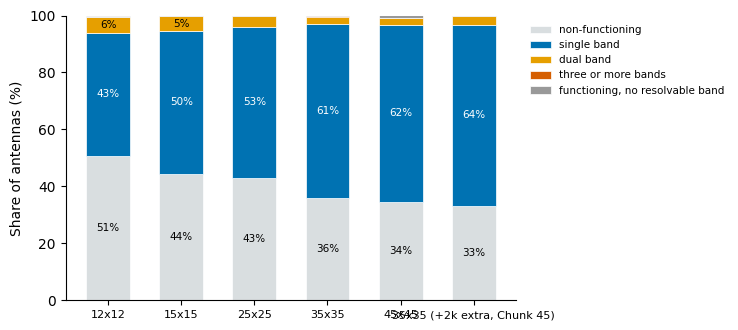

# Chunk 47 — Single-band vs multi-band antennas per grid

Every antenna in each processed dataset (all splits). Functioning = true minimum below −10 dB. A band = a true-curve dip below −10 dB with ≥ 3 dB prominence, ≥ 150 MHz from the next; a dip at the band edge (1 or 4 GHz) counts as a band.

## Whole dataset per grid
| dataset                     |   antennas |   functioning_pct |   non-functioning (%) |   single band (%) |   dual band (%) |   three or more bands (%) |   functioning, no resolvable band (%) |   functioning but NOT single band (% of all) |   functioning but NOT single band (% of functioning) |
|:----------------------------|-----------:|------------------:|----------------------:|------------------:|----------------:|--------------------------:|--------------------------------------:|---------------------------------------------:|-----------------------------------------------------:|
| 12x12                       |       7000 |              49.2 |                  50

In [7]:
# ── Figure and report ──
colors = {'non-functioning': '#D9DEE0', 'single band': '#0072B2', 'dual band': '#E69F00',
          'three or more bands': '#D55E00', 'functioning, no resolvable band': '#999999'}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(ALL)); bottom = np.zeros(len(ALL))
for k in CATS:
    v = ALL[f'{k} (%)'].values
    if v.sum() == 0: continue
    ax.bar(x, v, 0.6, bottom=bottom, color=colors[k], label=k, edgecolor='white', lw=0.5)
    for xi, vi, bi in zip(x, v, bottom):
        if vi >= 4: ax.text(xi, bi + vi / 2, f'{vi:.0f}%', ha='center', va='center', fontsize=7.5,
                            color='white' if k in ('single band', 'three or more bands') else 'black')
    bottom += v
ax.set_xticks(x); ax.set_xticklabels(ALL.dataset, fontsize=8); ax.set_ylabel('Share of antennas (%)'); ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=7.5, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT('ch47_band_distribution.png'), dpi=200); plt.show()

L = ['# Chunk 47 — Single-band vs multi-band antennas per grid', '',
     'Every antenna in each processed dataset (all splits). Functioning = true minimum below −10 dB. A band = a true-curve dip '
     'below −10 dB with ≥ 3 dB prominence, ≥ 150 MHz from the next; a dip at the band edge (1 or 4 GHz) counts as a band.', '',
     '## Whole dataset per grid',
     ALL[['dataset', 'antennas', 'functioning_pct'] + [f'{k} (%)' for k in CATS] +
         ['functioning but NOT single band (% of all)', 'functioning but NOT single band (% of functioning)']].round(1).to_markdown(index=False), '',
     '## Per split', BYSPLIT.round(1).to_markdown(index=False), '',
     '## Sensitivity: functioning but NOT single band (% of functioning) vs prominence threshold',
     SENS.pivot(index='dataset', columns='prominence_db', values='functioning_not_single_pct_of_functioning').loc[order].round(1).to_markdown()]
open(OUT('ch47_report.md'), 'w').write('\n'.join(L) + '\n'); print('\n'.join(L[:8]))
print('\nwritten:', sorted(Path(p).name for p in glob.glob(f'{ART}/ch47_*')))